# MT response and a measured QC decision

**Question:** What does the measured Clear Lake cl061 tensor support, and why must its failed screen remain QC-only?

**Level 1 — Foundations**  
**Prerequisites:** Python basics; 35 min.



## Objectives

Question: Which measured cl061 diagnostics are usable when its necessary 1D tensor-consistency gate fails?



## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.



## Data

Measured QC-only record plus a separate seeded synthetic calibration artifact; never merge these evidence classes.


**Source and rights:** Clear Lake station cl061 EDI, USGS/EarthScope [station product](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061), raw object [USGS-GMEG.2022.cl061.edi](https://data.earthscope.org/archive/seismology/products/emtf/surveys/2022/MT_TF_USGS-GMEG.2022.cl061/USGS-GMEG.2022.cl061.edi), and [USGS Clear Lake release](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california). The source release is marked CC0; the EDI requests citation. This repository uses the attributed QC derivative only and does not redistribute another raw EDI copy. cl061 remains QC-only because its 1D eligibility gate fails.

## Method

Clear Lake `cl061` is measured field data with 42 frequencies and unknown subsurface truth. Its committed screen fails the necessary 1D tensor-consistency test; it remains **QC-only** and must not be fit with the layered inverse. This lesson applies the implemented `mt_field_qc.tensor_gate` and `phase_tensor_diagnostic` directly to the committed tensor and marginal uncertainties. It also inspects the supplied tipper, which is ancillary evidence and is never an input to the 1D solver.

The EDI rotation is preserved in its supplied frame (`rotation_action: none`); no covariance-free re-rotation is attempted. The module checks that its geometric distance to an ideal 1D tensor is invariant under a quarter-turn, a diagnostic property rather than a reprocessing of this station. Tipper variance is explicitly uninterpreted in the source receipt, so plot component magnitude and missing frequencies only; do not form normalized tipper residuals or error bars from it.

With `exp(+iωt)`, `Z=E/H` is in Ω, apparent resistivity `ρₐ=|Z|²/(μ₀ω)` in Ω·m, phase in degrees and period `T=1/f` in seconds. The screen is a necessary consistency null, not proof of dimensionality. A failure cannot be repaired by tuning a 1D fit.
### cl061 eligibility boundary

The measured 42-period tensor fails both stored and recomputed 1D gates; phase tensor and tipper stay ancillary QC evidence.

In [1]:
# Apply implemented product QC diagnostics to the measured tensor; do not fit cl061.
import json, sys
from pathlib import Path
import numpy as np
from importlib.metadata import version

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from mt_field_qc import tensor_gate, phase_tensor_diagnostic

case = json.loads((root / "data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
f = np.asarray(case["frequencies_hz"], float)
period = 1 / f
z = np.asarray(case["tensor"]["real"]) + 1j * np.asarray(case["tensor"]["imag"])
sigma = np.asarray(case["tensor"]["sigma"], float)
gate = tensor_gate(z, sigma**2)  # Receipt stores marginal SD; the QC function accepts variance.
phase_qc = phase_tensor_diagnostic(z)
tip = case["metadata"]["tipper"]
print("Runtime:", {name: version(name) for name in ("numpy", "matplotlib", "scipy")})
print("Measured source:", case["id"], case["source_kind"], "N=", len(f), "truth=", case["truth"])
print(
    "Eligibility:",
    case["one_d_inversion_eligible"],
    "stored screen:",
    case["compatibility"]["passes_screen"],
    "recomputed:",
    gate["passes"],
)
print("QC scores:", list(gate["per_period_normalized"]), "limit:", gate["threshold"])
print("Quarter-turn geometric invariance max error:", gate["quarter_turn_invariance_max_abs_error"])


Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Measured source: cl061 measured EDI transfer functions N= 42 truth= None
Eligibility: False stored screen: False recomputed: False
QC scores: ['xx', 'yy', 'antisymmetry'] limit: 3.0
Quarter-turn geometric invariance max error: 1.1102230246251565e-16


### Inspect phase tensor and tipper diagnostics

The invariant impedance gate above reports measured-period scores and eligibility separately. Here the phase-tensor and tipper receipt fields are surfaced independently; they do not change the Clear Lake case from QC-only status.

In [2]:
# Inspect phase tensor and tipper diagnostics.
print(
    "Usable phase-tensor periods:",
    phase_qc["usable_periods"],
    "median scalar departure:",
    phase_qc["median_scalar_departure"],
)
print(
    "Tipper present:",
    tip["present"],
    "used by 1D inverse:",
    tip["used_in_1d_inversion"],
    "variance:",
    tip["raw_variance_convention"],
)


Usable phase-tensor periods: 42 median scalar departure: 0.257651139958079
Tipper present: True used by 1D inverse: False variance: uninterpreted EDI native variance


### Diagnostic 2 — Recompute tensor QC and inspect ancillary tipper

The upper-right panel shows the three noise-normalized necessary 1D checks by period. The lower-right overlay shows phase-tensor scalar departure and raw tipper magnitude; these are QC clues, not a 1D inversion target. Missing tipper periods remain missing.

Plot impedance and the 1D-consistency gate first; then add phase tensor and tipper diagnostics.

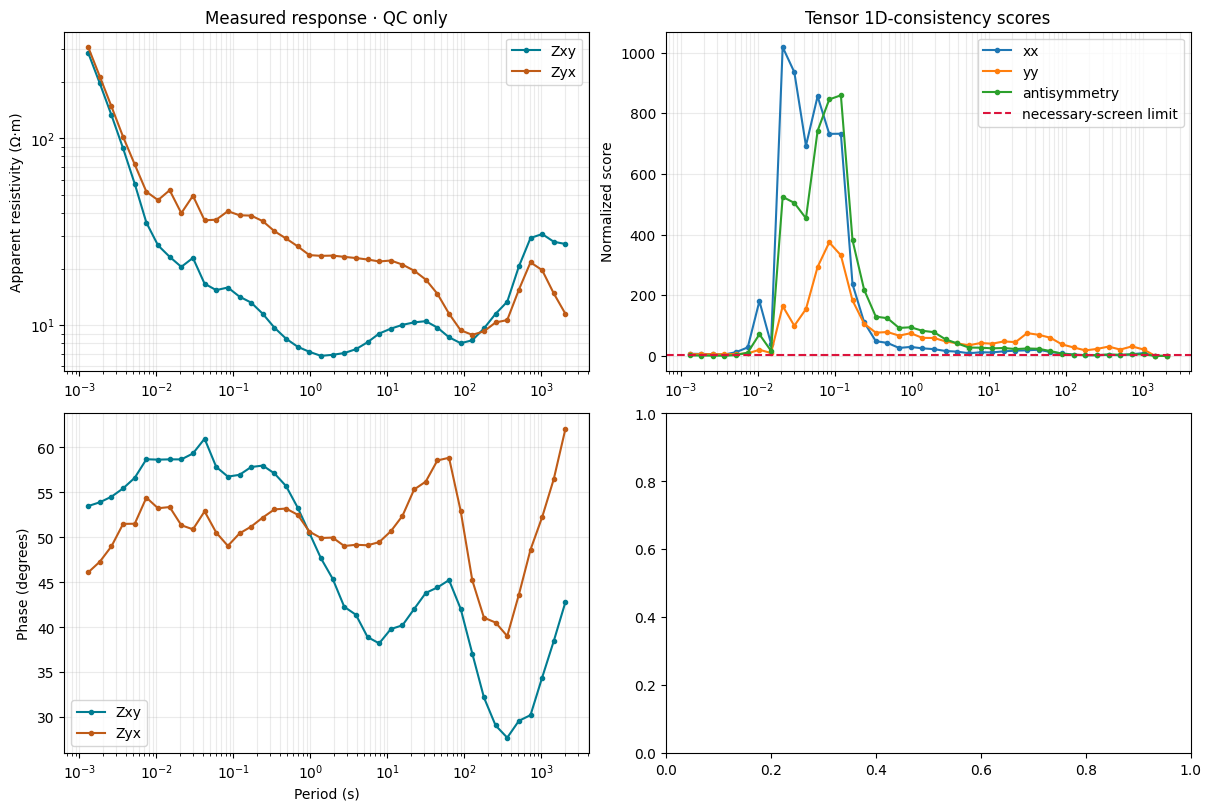

In [3]:
# Plot impedance and the necessary 1D tensor gate.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for name, color in (("xy", "#007c91"), ("yx", "#bf5b17")):
    response = case["observed"][name]
    ax[0, 0].loglog(period, response["apparent"], ".-", label="Z" + name, color=color)
    ax[1, 0].semilogx(period, response["phase"], ".-", label="Z" + name, color=color)
ax[0, 0].set_ylabel("Apparent resistivity (Ω·m)")
ax[1, 0].set_ylabel("Phase (degrees)")
ax[1, 0].set_xlabel("Period (s)")
for axis in (ax[0, 0], ax[1, 0]):
    axis.grid(True, which="both", alpha=0.25)
    axis.legend()
ax[0, 0].set_title("Measured response · QC only")
for key, score in gate["per_period_normalized"].items():
    ax[0, 1].semilogx(period, score, ".-", label=key)
ax[0, 1].axhline(gate["threshold"], color="crimson", ls="--", label="necessary-screen limit")
ax[0, 1].set_title("Tensor 1D-consistency scores")
ax[0, 1].set_ylabel("Normalized score")
ax[0, 1].legend()
ax[0, 1].grid(True, which="both", alpha=0.25)


The first panel compares the two measured impedance orientations with the necessary 1D consistency screen. The next panel overlays phase-tensor departure and raw tipper magnitude; two tipper periods are absent and its variance has no interpreted uncertainty. These plots support QC triage of cl061 only: they do not justify fitting the failed record or infer a layered resistivity model.


In [4]:
# Add phase-tensor diagnostics and raw tipper magnitudes without interpreting variance.
pt = phase_qc["per_period"]
pt_period = np.asarray([period[row["source_index"]] for row in pt])
pt_departure = np.asarray([row["scalar_departure"] for row in pt])
ax[1, 0].set_title("Measured phase response")
ax[1, 1].semilogx(pt_period, pt_departure, "o", ms=4, color="#7651a8")
ax[1, 1].set_title("Phase-tensor scalar departure")
ax[1, 1].set_ylabel("Relative departure (dimensionless)")
ax[1, 1].set_xlabel("Period (s)")
ax[1, 1].grid(True, which="both", alpha=0.25)
tx = np.asarray(tip["components"]["X"]["real"], dtype=float)
tx = tx + 1j * np.asarray(tip["components"]["X"]["imag"], dtype=float)
ty = np.asarray(tip["components"]["Y"]["real"], dtype=float)
ty = ty + 1j * np.asarray(tip["components"]["Y"]["imag"], dtype=float)
axis = ax[1, 1].twinx()
axis.semilogx(period, np.abs(tx), "s", ms=3, color="#007c91", alpha=0.65, label="|Tx|")
axis.semilogx(period, np.abs(ty), "^", ms=3, color="#bf5b17", alpha=0.65, label="|Ty|")
axis.set_ylabel("Tipper magnitude (dimensionless)")
handles, labels = ax[1, 1].get_legend_handles_labels()
tipper_handles, tipper_labels = axis.get_legend_handles_labels()
axis.legend(handles + tipper_handles, labels + tipper_labels, fontsize=8, loc="best")
fig.suptitle("Clear Lake cl061 measured evidence — QC only; no layered fit")
plt.show()
print("Tipper missing frequencies (Hz):", tip["missing_frequency_hz"])
print("Tipper variance is uninterpreted; no tipper uncertainty bars are shown.")


Tipper missing frequencies (Hz): [0.0004882812, 0.0006915263]
Tipper variance is uninterpreted; no tipper uncertainty bars are shown.


Recompute the necessary screen with twice the component standard deviations.

In [5]:
# Recompute the necessary screen with twice the component standard deviations.
looser_gate = tensor_gate(z, (2 * sigma) ** 2)
print("2x sigma WRMS:", looser_gate["wrms"])


2x sigma WRMS: {'xx': 160.11663013231475, 'yy': 54.753939889373655, 'antisymmetry': 133.80001937595154}


Recompute it with half the standard deviations to expose QC sensitivity.

In [6]:
# Recompute it with half the standard deviations to expose QC sensitivity.
tighter_gate = tensor_gate(z, (0.5 * sigma) ** 2)
print("0.5x sigma WRMS:", tighter_gate["wrms"])


0.5x sigma WRMS: {'xx': 640.466520529259, 'yy': 219.01575955749462, 'antisymmetry': 535.2000775038061}


## Results

The dataset remains QC-only because the 1D eligibility screen fails; its tensor and tipper diagnostics are not a layered-earth inversion. Missing tipper periods remain missing.

**Answer:** All 42 impedance periods are available to the phase-tensor calculation, whose median scalar departure is 0.257651. The stored and recomputed 1D eligibility gates both fail; two tipper frequencies are missing, and tipper uncertainty remains uninterpreted.


## Summary

This measured EDI supports QC review only. The failed gate excludes cl061 from the 1D inversion lesson; neither phase-tensor departure nor incomplete tipper coverage rescues that eligibility decision or supplies subsurface truth.



## References

- [MTpy v2](https://github.com/MTgeophysics/mtpy-v2)
- [USGS Clear Lake magnetotelluric data](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)



The measured Clear Lake cl061 record is handled strictly as QC evidence. The committed tensor and marginal variances are inputs to the product’s current necessary one-dimensional gate and phase-tensor diagnostic. The gate checks all supplied frequencies and records normalized diagonal and antisymmetry departures. A failed gate does not mean the measured EDI is useless; it means this layered one-dimensional inverse is not eligible under the product’s declared screen. Do not tune a frequency window until the screen passes or feed cl061 into the synthetic fitter. Keep its original frequency grid, missing ancillary tipper entries, measured status and failed result intact.

EarthScope cl061 product record: https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061. The USGS dataset DOI, citation and CC0 derivative-only decision are stated in Data above.